# 03 · RFM segmentation: who comes back, and who is worth targeting?

Notebook 02 showed that almost nobody returns (≈2%) and that late delivery is not the main cause.
This notebook asks **which customers and categories do retain**, so the business knows where to focus.

**RFM** scores each customer on:
- **R**ecency: days since their last order (lower is better)
- **F**requency: number of separate purchase days
- **M**onetary: total spend (BRL, items + freight)

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
con = duckdb.connect("../data/olist.duckdb", read_only=True)

## 1 · Build the RFM table
Recency is measured from the day after the last order in the dataset. Frequency counts distinct purchase **days**, so a split basket counts once.

In [2]:
rfm = con.execute("""
WITH delivered AS (SELECT * FROM fct_orders WHERE order_status = 'delivered'),
ref AS (SELECT MAX(purchased_at) + INTERVAL 1 DAY AS ref_date FROM delivered)
SELECT
    customer_unique_id,
    DATE_DIFF('day', MAX(purchased_at), (SELECT ref_date FROM ref)) AS recency,
    COUNT(DISTINCT CAST(purchased_at AS DATE))                     AS frequency,
    SUM(order_value)                                               AS monetary,
    AVG(review_score)                                              AS avg_review
FROM delivered
GROUP BY customer_unique_id
""").df()

print(f"{len(rfm):,} customers")
rfm[["recency", "frequency", "monetary"]].describe().round(1)

93,358 customers


,recency,frequency,monetary
count,93358.0,93358.0,93358.0
mean,238.5,1.0,165.2
std,152.6,0.2,226.3
min,1.0,1.0,9.6
25%,115.0,1.0,63.0
50%,219.0,1.0,107.8
75%,347.0,1.0,182.5
max,714.0,15.0,13664.1


In [3]:
rfm["frequency"].value_counts().sort_index().to_frame("customers")

,customers
frequency,
1,91343
2,1864
3,120
4,17
5,6
6,5
7,2
15,1


## 2 · Score and segment

Classic RFM gives every dimension a 1–5 quintile score. That doesn't work for **F** here: 98% of customers have frequency = 1, so quintiles can't split them.
So **R** and **M** get quintile scores (5 = best), and **F** is used directly as *one-time* vs *repeat*.

In [4]:
rfm["R"] = pd.qcut(rfm["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)   # recent = 5
rfm["M"] = pd.qcut(rfm["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)   # big spend = 5

def segment(row):
    if row.frequency >= 2:
        return "Champions" if row.R >= 4 else "Lapsing repeaters"
    if row.R >= 4:
        return "High-value new" if row.M >= 4 else "Recent one-timers"
    if row.R >= 2:
        return "Big spenders at risk" if row.M >= 4 else "Fading one-timers"
    return "Lost"

rfm["segment"] = rfm.apply(segment, axis=1)

order = ["Champions", "Lapsing repeaters", "High-value new", "Recent one-timers",
         "Big spenders at risk", "Fading one-timers", "Lost"]
seg = (rfm.groupby("segment")
          .agg(customers=("customer_unique_id", "count"),
               revenue=("monetary", "sum"),
               avg_spend=("monetary", "mean"),
               avg_recency_days=("recency", "mean"),
               avg_review=("avg_review", "mean"))
          .reindex(order))
seg["customer_share_%"] = 100 * seg["customers"] / seg["customers"].sum()
seg["revenue_share_%"]  = 100 * seg["revenue"]  / seg["revenue"].sum()
seg.round(1)

,customers,revenue,avg_spend,avg_recency_days,avg_review,customer_share_%,revenue_share_%
segment,,,,,,,
Champions,1069,349844.9,327.3,88.1,4.3,1.1,2.3
Lapsing repeaters,946,296450.1,313.4,309.6,4.3,1.0,1.9
High-value new,14614,4419803.9,302.4,92.6,4.1,15.7,28.7
Recent one-timers,21876,1595922.3,73.0,90.8,4.3,23.4,10.3
Big spenders at risk,14149,4172989.9,294.9,269.0,4.0,15.2,27.1
Fading one-timers,22308,1618853.0,72.6,269.2,4.1,23.9,10.5
Lost,18396,2965909.6,161.2,474.3,4.2,19.7,19.2


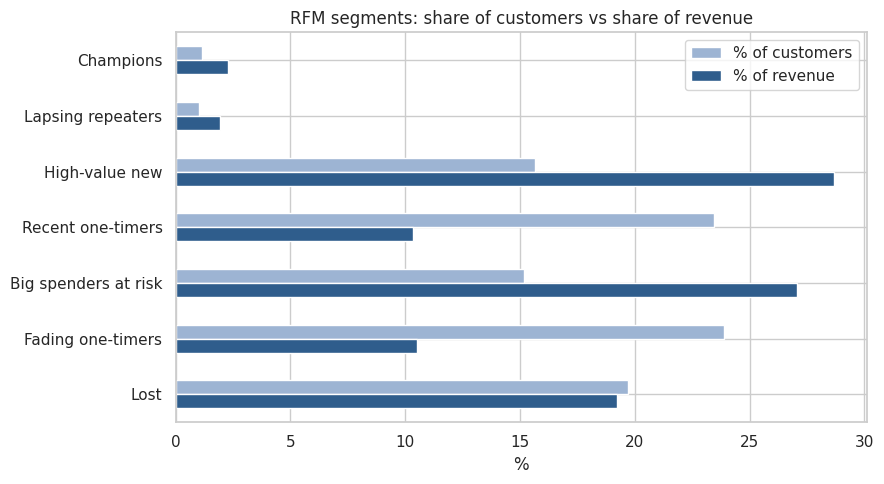

In [5]:
plot = seg[["customer_share_%", "revenue_share_%"]].rename(
    columns={"customer_share_%": "% of customers", "revenue_share_%": "% of revenue"})
ax = plot.plot.barh(figsize=(9, 5), color=["#9DB4D3", "#2F5D8C"])
ax.invert_yaxis(); ax.set_xlabel("%"); ax.set_ylabel("")
ax.set_title("RFM segments: share of customers vs share of revenue")
plt.tight_layout(); plt.savefig(FIG + "rfm_segments.png", dpi=150); plt.show()

## 3 · Which first-purchase categories bring customers back?
Same strict repeat definition as notebook 02: a later-day order within 180 days, first orders before Mar 2018. Categories with at least 500 customers.

In [6]:
cat = con.execute("""
WITH delivered AS (
    SELECT * FROM fct_orders WHERE order_status = 'delivered' AND delivered_at IS NOT NULL
),
ranked AS (
    SELECT *, ROW_NUMBER() OVER (PARTITION BY customer_unique_id ORDER BY purchased_at) AS rn
    FROM delivered
),
first_order AS (SELECT * FROM ranked WHERE rn = 1 AND purchased_at < '2018-03-01'),
first_cat AS (                      -- main category of the first order
    SELECT f.customer_unique_id, f.purchased_at,
           MODE(p.category) AS category
    FROM first_order f
    JOIN raw_order_items i USING (order_id)
    JOIN dim_products   p USING (product_id)
    GROUP BY 1, 2
)
SELECT fc.customer_unique_id, fc.category,
       MAX(CASE WHEN CAST(d.purchased_at AS DATE) > CAST(fc.purchased_at AS DATE)
                 AND d.purchased_at <= fc.purchased_at + INTERVAL 180 DAY
                THEN 1 ELSE 0 END) AS repeat_180d
FROM first_cat fc
LEFT JOIN delivered d USING (customer_unique_id)
GROUP BY ALL
""").df()

big = cat.groupby("category").filter(lambda g: len(g) >= 500)
cat_tbl = (big.groupby("category")["repeat_180d"]
              .agg(customers="count", repeat_rate="mean")
              .sort_values("repeat_rate", ascending=False))
cat_tbl["repeat_rate_%"] = (100 * cat_tbl["repeat_rate"]).round(2)

chi2, p, dof, _ = stats.chi2_contingency(pd.crosstab(big["category"], big["repeat_180d"]))
print(f"Overall repeat rate: {100 * big['repeat_180d'].mean():.2f}%")
print(f"Category vs repeat: chi2 = {chi2:.1f}, dof = {dof}, p = {p:.2g}")
cat_tbl[["customers", "repeat_rate_%"]]

Overall repeat rate: 1.99%
Category vs repeat: chi2 = 69.9, dof = 21, p = 3.6e-07


,customers,repeat_rate_%
category,,
fashion_bags_accessories,1135,3.26
pet_shop,817,3.06
bed_bath_table,5361,2.74
sports_leisure,4503,2.62
furniture_decor,3721,2.31
perfumery,1973,2.13
garden_tools,2310,2.12
health_beauty,4344,2.00
baby,1494,1.94


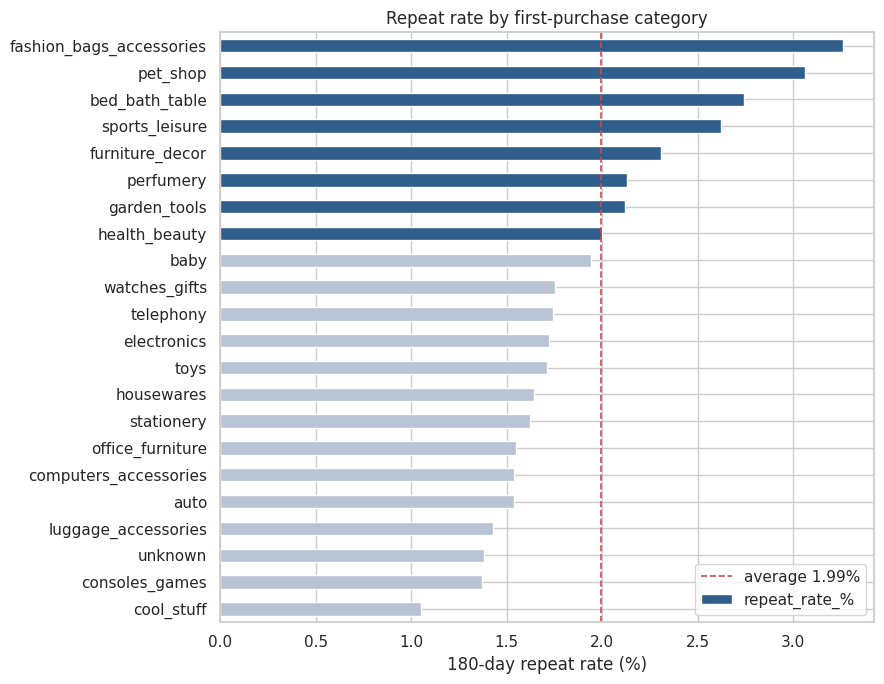

In [7]:
avg = 100 * big["repeat_180d"].mean()
colors = ["#2F5D8C" if v > avg else "#B8C4D3" for v in cat_tbl["repeat_rate_%"]]
ax = cat_tbl["repeat_rate_%"].plot.barh(figsize=(9, 7), color=colors)
ax.axvline(avg, color="#C44E52", ls="--", lw=1.2, label=f"average {avg:.2f}%")
ax.invert_yaxis(); ax.set_xlabel("180-day repeat rate (%)"); ax.set_ylabel("")
ax.set_title("Repeat rate by first-purchase category")
ax.legend(); plt.tight_layout(); plt.savefig(FIG + "repeat_by_category.png", dpi=150); plt.show()

## Conclusions

1. **Repeat customers are rare but valuable.** Champions + Lapsing repeaters are just **2.2%** of customers but **4.2%** of revenue. They spend about **2× the average** (≈ R$320 vs R$165).
2. **The money sits with high-value one-timers.** *High-value new* (15.7% of customers → **28.7%** of revenue) and *Big spenders at risk* (15.2% → **27.1%**) together make up **31% of customers and 56% of revenue**. These are the people to win a second order from.
3. **Category matters** (χ² p ≈ 3e-7). First purchases in **fashion bags & accessories (3.3%)**, **pet shop (3.1%)**, **bed/bath/table (2.7%)** and **sports & leisure (2.6%)** lead to repeats at up to **3× the rate** of *cool_stuff* (1.1%). Those are replenishable, everyday categories, while one-off purchases such as electronics, consoles and office furniture rarely bring people back.

**Recommendation:** send a targeted second-purchase campaign (voucher or reminder within ~90 days) to *High-value new* customers whose first order was in a high-repeat category. Re-engage *Big spenders at risk* before they move to *Lost*.